# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%cd /content/drive/MyDrive/'3rd Year'/Systems

/content/drive/MyDrive/3rd Year/Systems


transactions: (25562, 8)
distributions: (5, 8)
locations: (14, 8)
product: (45, 7)
daily_sales: (3600, 5)
inventory: (4320, 6)
rows: 45 | unique SKUs: 45
exact duplicate rows: 0

missing values:
 sku              0
product_name     0
category         0
subcategory     13
unit_cost        5
supplier         0
package_size     0
dtype: int64

raw category labels:
 category
Emergency              5
Emergency Supplies     3
EMERGENCY              3
ENTERTAINMENT          3
GROCERY                3
Breakfast              2
entertainment          2
household              2
ELECTRONICS            2
health                 2
Baby                   2
Electronics            1
ALCOHOL                1
Alcoholic Beverages    1
breakfast              1
Breakfast Foods        1
Groceries              1
Grocery                1
electronics            1
snacks                 1
grocery                1
HOUSEHOLD              1
Snacks                 1
Household              1
baby                   1
B

,sku,product_name,category,unit_cost,canonical_sku,product_name_clean,category_clean,unit_cost_missing
0,PT-12,pop-tarts strawberry,Breakfast Foods,1.93,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,False
1,SKU#459812,Strawberry Pop-Tart,Breakfast,2.26,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,False
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,2.11,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,False
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,NaN,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,True
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,2.64,WATER24PK,Bottled Water 24-Pack,Emergency,False
5,WATER24PK,Bottled Water 24-Pack,Emergency,2.38,WATER24PK,Bottled Water 24-Pack,Emergency,False
6,WTR_24PK,Water - 24 Pack,Emergency,2.08,WATER24PK,Bottled Water 24-Pack,Emergency,False
7,BATT-100,BATTERIES AA 4PK,Emergency Supplies,NaN,BAT-AA4,AA Batteries 4-Pack,Emergency,True
8,BAT-AA4,AA Batteries 4-Pack,Emergency Supplies,4.16,BAT-AA4,AA Batteries 4-Pack,Emergency,False
9,BATT_AA_4PK,AA Batteries 4-Pack,Emergency,3.71,BAT-AA4,AA Batteries 4-Pack,Emergency,False


,File,Issue,Decision,Rows affected,Reason
0,product_catalog.csv,27 different spellings for 10 categories,Standardize category labels to the 10 names used in the database,32,Matching the database names lets us join to daily_sales_summary for Q5.
1,product_catalog.csv,45 SKUs for only 20 real products,"Map every SKU to one canonical SKU (name-matching found 34, the other 11 matched by hand)",25,Fragmented SKUs hide true demand (the Q2 Pop-Tarts effect).
2,product_catalog.csv,Different pack sizes listed within one product family (e.g. Pop-Tarts 4-pack vs 6-pack),Merge different pack sizes into one product,37,"package_size contradicts the product names (Bottled Water 24PK is listed as '1 pack'), so it can't be trusted to split products."
3,product_catalog.csv,Board games and playing cards share the Entertainment category,Keep them as separate canonical products inside one category,5,Q5 has to test whether the +250% board-game surge is really playing cards lumped in.
4,product_catalog.csv,Missing unit_cost values,"Flag with unit_cost_missing, don't fill",5,"No question needs unit_cost (revenue comes from transaction unit_price), so filling it would invent data."
5,product_catalog.csv,"supplier, subcategory and package_size are unreliable",Drop these three columns,45,"Suppliers are wrong (Hasbro supplies beer), subcategories are cut off ('First', 'Peanut'), pack sizes contradict names."


(25562, 8)


,0
transaction_id,object
store_id,object
timestamp,object
sku,object
product_name,object
category,object
quantity,int64
unit_price,object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25562 entries, 0 to 25561
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   transaction_id  25562 non-null  object
 1   store_id        25562 non-null  object
 2   timestamp       24676 non-null  object
 3   sku             25562 non-null  object
 4   product_name    25562 non-null  object
 5   category        25562 non-null  object
 6   quantity        25562 non-null  int64 
 7   unit_price      25562 non-null  object
dtypes: int64(1), object(7)
memory usage: 1.6+ MB


... (50 outputs left out)

,date,orders,precipitation_sum,wind_speed_10m_max,pressure_msl_mean,source
0,2024-09-01,42,3.0,18.8,1014.1,open-meteo
1,2024-09-02,46,12.4,13.5,1014.1,open-meteo
2,2024-09-03,48,24.9,22.8,1015.7,open-meteo
3,2024-09-04,47,22.1,15.5,1017.8,open-meteo
4,2024-09-05,60,23.1,15.2,1017.3,open-meteo


,date,category_clean,total_units,precipitation_sum,wind_speed_10m_max,pressure_msl_mean
0,2024-09-01,Alcohol,5,3.0,18.8,1014.1
1,2024-09-01,Baby,4,3.0,18.8,1014.1
2,2024-09-01,Breakfast,6,3.0,18.8,1014.1
3,2024-09-01,Electronics,3,3.0,18.8,1014.1
4,2024-09-01,Emergency,31,3.0,18.8,1014.1


,baseline_daily_units,surge_daily_units,additional_daily_units,percent_increase
category_clean,,,,
Breakfast,73.93,376.86,302.93,409.76
Emergency,356.57,1006.43,649.86,182.25
Electronics,69.93,175.86,105.93,151.48
Alcohol,61.57,138.86,77.29,125.52
Health,42.36,95.0,52.64,124.28
Entertainment,102.64,228.57,125.93,122.69
Household,85.36,176.29,90.93,106.53
Grocery,172.29,306.57,134.29,77.94
Baby,85.21,133.71,48.5,56.92


,baseline_daily_units,surge_daily_units,percent_increase
category_clean,,,
Breakfast,73.93,376.86,409.76
Emergency,356.57,1006.43,182.25
Electronics,69.93,175.86,151.48
Alcohol,61.57,138.86,125.52
Health,42.36,95.0,124.28


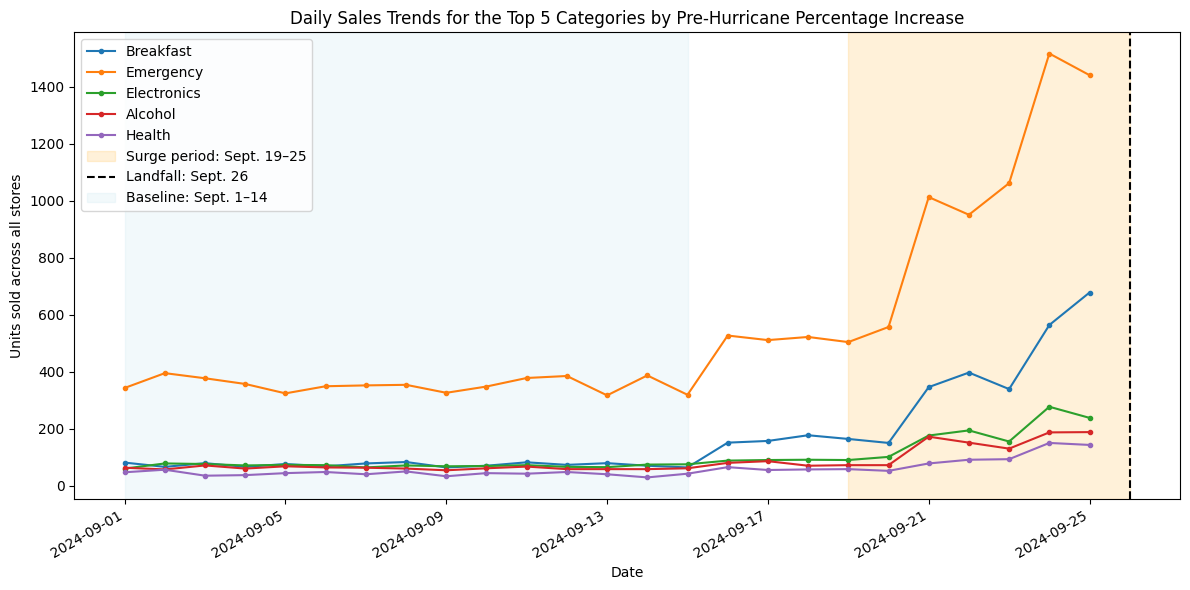

,sku,canonical_sku,product_name_clean,category_clean
0,PT-12,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
1,SKU#459812,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
2,POPTART-STRAW,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
3,PT_STRAWBERRY,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast


Unmapped transaction SKUs: []


sku,POPTART-STRAW,PT-12,PT_STRAWBERRY,SKU#459812,consolidated_units
date,,,,,
2024-09-01,18,30,13,20,81
2024-09-02,24,23,9,10,66
2024-09-03,11,17,25,26,79
2024-09-04,19,8,26,13,66
2024-09-05,11,30,14,21,76
2024-09-06,18,17,11,22,68
2024-09-07,25,7,20,26,78
2024-09-08,20,32,14,17,83
2024-09-09,28,9,16,11,64


Total dated, valid Pop-Tarts units: 5005
Original SKU count: 4
Canonical product count: 1
Peak sales date: 2024-09-25
Peak daily units: 678


,total_units
sku,
POPTART-STRAW,1239
PT-12,1332
PT_STRAWBERRY,1230
SKU#459812,1204


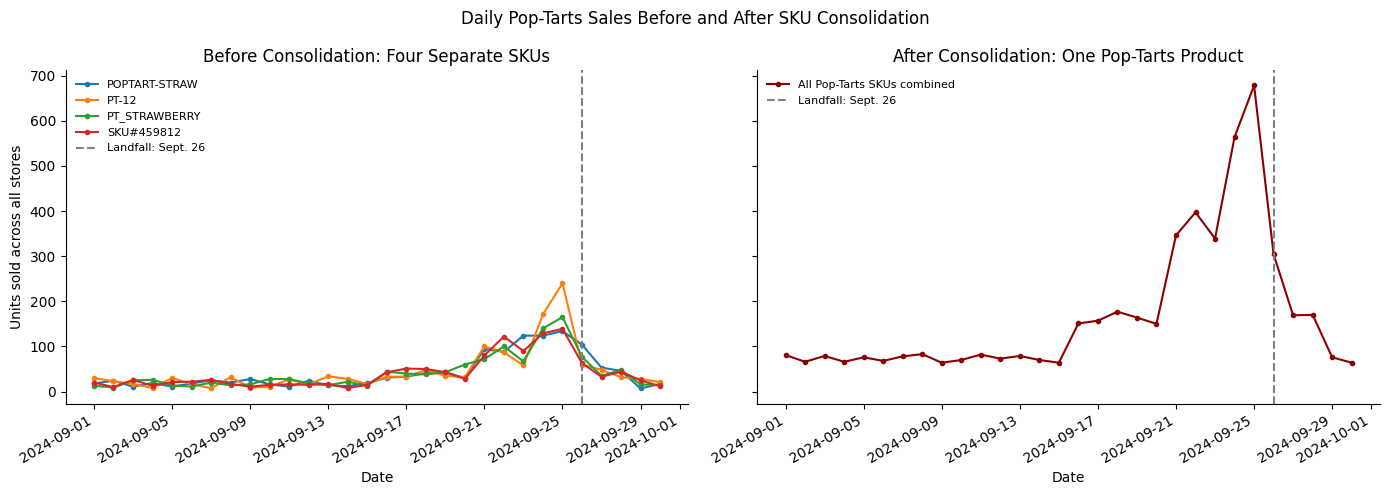

Stores with weather: 11
Skipped (no coordinates): ['FL-619']


,date,precipitation_sum,wind_speed_10m_max,pressure_msl_mean,store_id
0,2024-09-01,6.4,18.7,1014.1,FL-239
1,2024-09-02,22.0,12.7,1014.1,FL-239
2,2024-09-03,32.7,20.6,1015.7,FL-239
3,2024-09-04,21.2,12.6,1017.7,FL-239
4,2024-09-05,20.8,15.2,1017.2,FL-239


_merge
both          3300
left_only      300
right_only       0
Name: count, dtype: int64
Sales rows with no weather (store has no coordinates): ['FL-619']
Rows analyzed: 3300 | stores: 11 | days: 30


,store_id,date,category_clean,units,baseline_units,sales_index,precipitation_sum,wind_speed_10m_max,pressure_msl_mean
0,FL-078,2024-09-01,Alcohol,3.0,4.857143,0.617647,1.5,11.3,1014.0
1,FL-078,2024-09-01,Baby,9.0,7.071429,1.272727,1.5,11.3,1014.0
2,FL-078,2024-09-01,Breakfast,4.0,5.357143,0.746667,1.5,11.3,1014.0
3,FL-078,2024-09-01,Electronics,4.0,6.428571,0.622222,1.5,11.3,1014.0
4,FL-078,2024-09-01,Emergency,27.0,30.571429,0.883178,1.5,11.3,1014.0


,Precipitation,Max wind speed,Mean pressure
category_clean,,,
Emergency,-0.30,0.26,-0.38
Breakfast,-0.29,0.25,-0.38
Entertainment,-0.18,0.27,-0.29
Electronics,-0.21,0.23,-0.27
Household,-0.16,0.22,-0.24
Health,-0.17,0.23,-0.22
Grocery,-0.28,0.17,-0.21
Alcohol,-0.18,0.15,-0.20
Baby,-0.24,0.07,-0.12


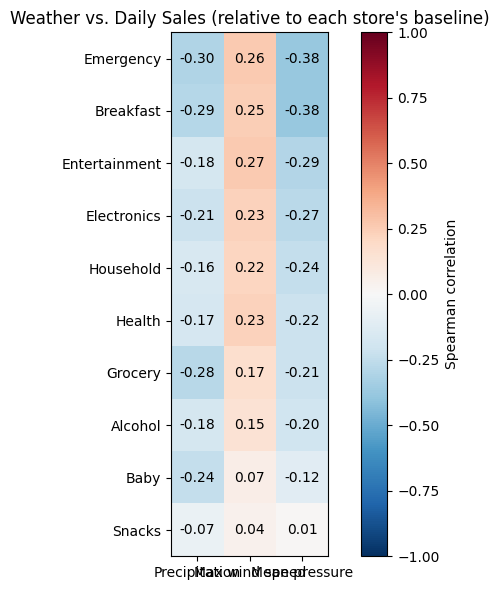

,Precipitation,Max wind speed,Mean pressure
lag_days,,,
-7,-0.14,-0.12,-0.41
-6,-0.25,-0.17,-0.51
-5,-0.39,-0.22,-0.51
-4,-0.53,-0.22,-0.37
-3,-0.45,-0.15,-0.31
-2,-0.41,0.01,-0.34
-1,-0.42,0.13,-0.37
0,-0.31,0.27,-0.39
1,-0.27,0.27,-0.43


,best_lag_days,correlation_at_best_lag,correlation_at_lag_0
Precipitation,-4,-0.53,-0.31
Max wind speed,4,0.35,0.27
Mean pressure,-6,-0.51,-0.39


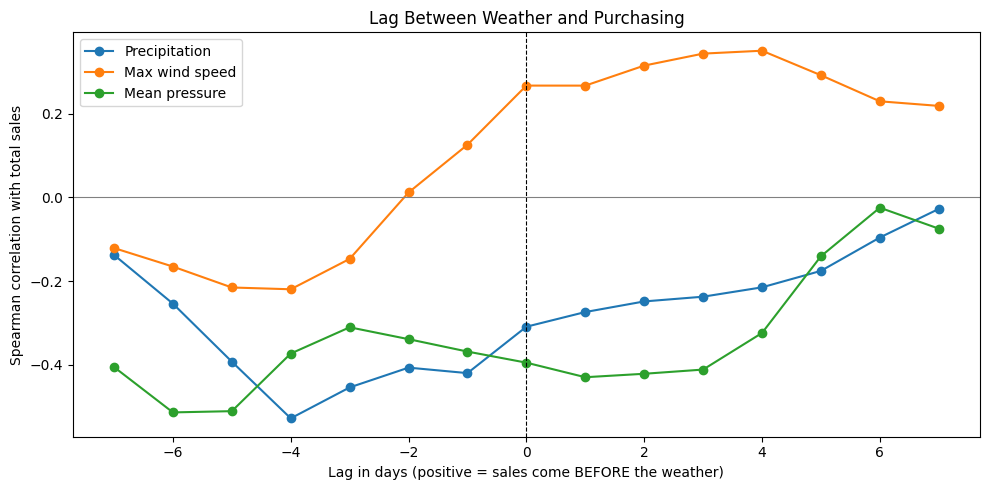

,store_id,store_name,city,region,latitude,longitude,coordinates_missing,miles_to_path,miles_to_landfall
7,FL-078,Walmart Supercenter Gainesville,Gainesville,North,29.6516,-82.3248,False,137.0,86.0
9,FL-445,Walmart Supercenter St. Petersburg,St. Petersburg,West,27.7676,-82.6403,False,148.0,167.0
11,FL-710,Walmart Supercenter Pensacola,Pensacola,Panhandle,30.4213,-87.2169,False,152.0,212.0
1,FL-105,Walmart Supercenter Tampa,Tampa,West,27.9506,-82.4572,False,155.0,160.0
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,North,30.3322,-81.6557,False,179.0,124.0
10,FL-302,Walmart Supercenter Lakeland,Lakeland,Central,28.0395,-81.9498,False,184.0,172.0
0,FL-239,Walmart Supercenter Orlando,Orlando,Central,28.5383,-81.3792,False,208.0,173.0
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Central,28.2920,-81.4076,False,211.0,182.0
6,FL-501,Walmart Supercenter Fort Myers,Fort Myers,West,26.6406,-81.8723,False,213.0,257.0
5,FL-156,Walmart Supercenter Daytona Beach,Daytona Beach,East,29.2108,-81.0228,False,218.0,170.0


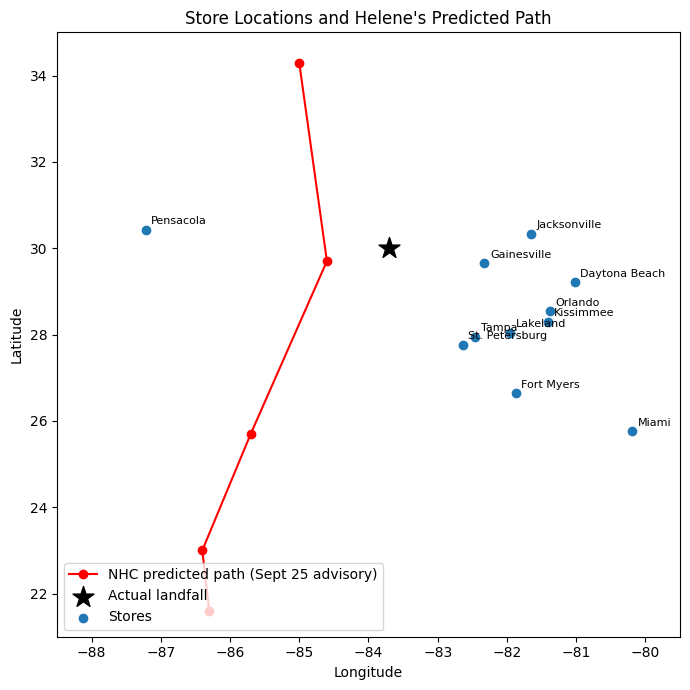

,store_id,baseline_daily_units,surge_daily_units,percent_increase,surge_onset,peak_day,onset_days_before_landfall,peak_days_before_landfall,city,store_name,miles_to_path,miles_to_landfall
0,FL-078,92.1,219.0,137.9,2024-09-16,2024-09-25,10,1,Gainesville,Walmart Supercenter Gainesville,137.0,86.0
8,FL-445,95.9,232.0,141.8,2024-09-16,2024-09-24,10,2,St. Petersburg,Walmart Supercenter St. Petersburg,148.0,167.0
11,FL-710,93.3,227.9,144.3,2024-09-16,2024-09-25,10,1,Pensacola,Walmart Supercenter Pensacola,152.0,212.0
1,FL-105,91.8,231.7,152.5,2024-09-16,2024-09-25,10,1,Tampa,Walmart Supercenter Tampa,155.0,160.0
7,FL-412,91.1,222.9,144.5,2024-09-16,2024-09-25,10,1,Jacksonville,Walmart Supercenter Jacksonville,179.0,124.0
5,FL-302,98.0,239.4,144.3,2024-09-16,2024-09-25,10,1,Lakeland,Walmart Supercenter Lakeland,184.0,172.0
3,FL-239,94.4,209.6,122.1,2024-09-16,2024-09-24,10,2,Orlando,Walmart Supercenter Orlando,208.0,173.0
4,FL-287,91.0,220.1,141.9,2024-09-17,2024-09-25,9,1,Kissimmee,Walmart Neighborhood Market Kissimmee,211.0,182.0
9,FL-501,93.1,220.6,137.0,2024-09-16,2024-09-24,10,2,Fort Myers,Walmart Supercenter Fort Myers,213.0,257.0
2,FL-156,95.2,229.1,140.7,2024-09-17,2024-09-24,9,2,Daytona Beach,Walmart Supercenter Daytona Beach,218.0,170.0


Distance vs. surge multiple: Spearman r = 0.05
(Negative r = stores closer to the path surged more)


,store_id,city,miles_from_path,surge_multiple,transactions
0,FL-078,Gainesville,137.0,2.38,2001
1,FL-445,St. Petersburg,148.0,2.42,2074
2,FL-710,Pensacola,152.0,2.44,2066
3,FL-105,Tampa,155.0,2.52,2043
4,FL-412,Jacksonville,179.0,2.45,2028
5,FL-302,Lakeland,184.0,2.44,2123
6,FL-239,Orlando,208.0,2.22,2010
7,FL-287,Kissimmee,211.0,2.42,2053
8,FL-501,Fort Myers,213.0,2.37,2002
9,FL-156,Daytona Beach,218.0,2.41,2074


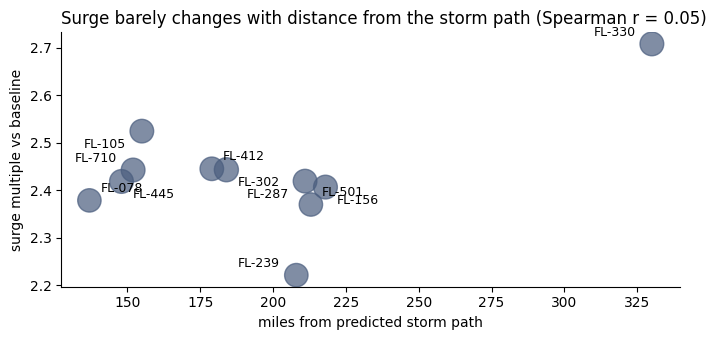

Smallest bubble: FL-078 (Gainesville) has 2,001 transactions, so its 2.4x is the least certain point.
Not plotted: FL-619 (Tallahassee), no coordinates.
Distance vs. days of early warning: Spearman r = -0.45
(Negative r = stores closer to the path started surging earlier)


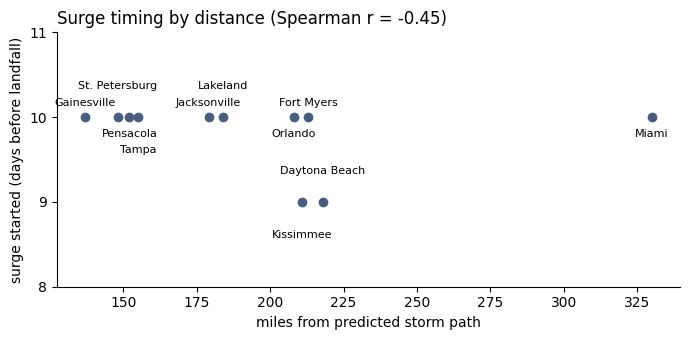

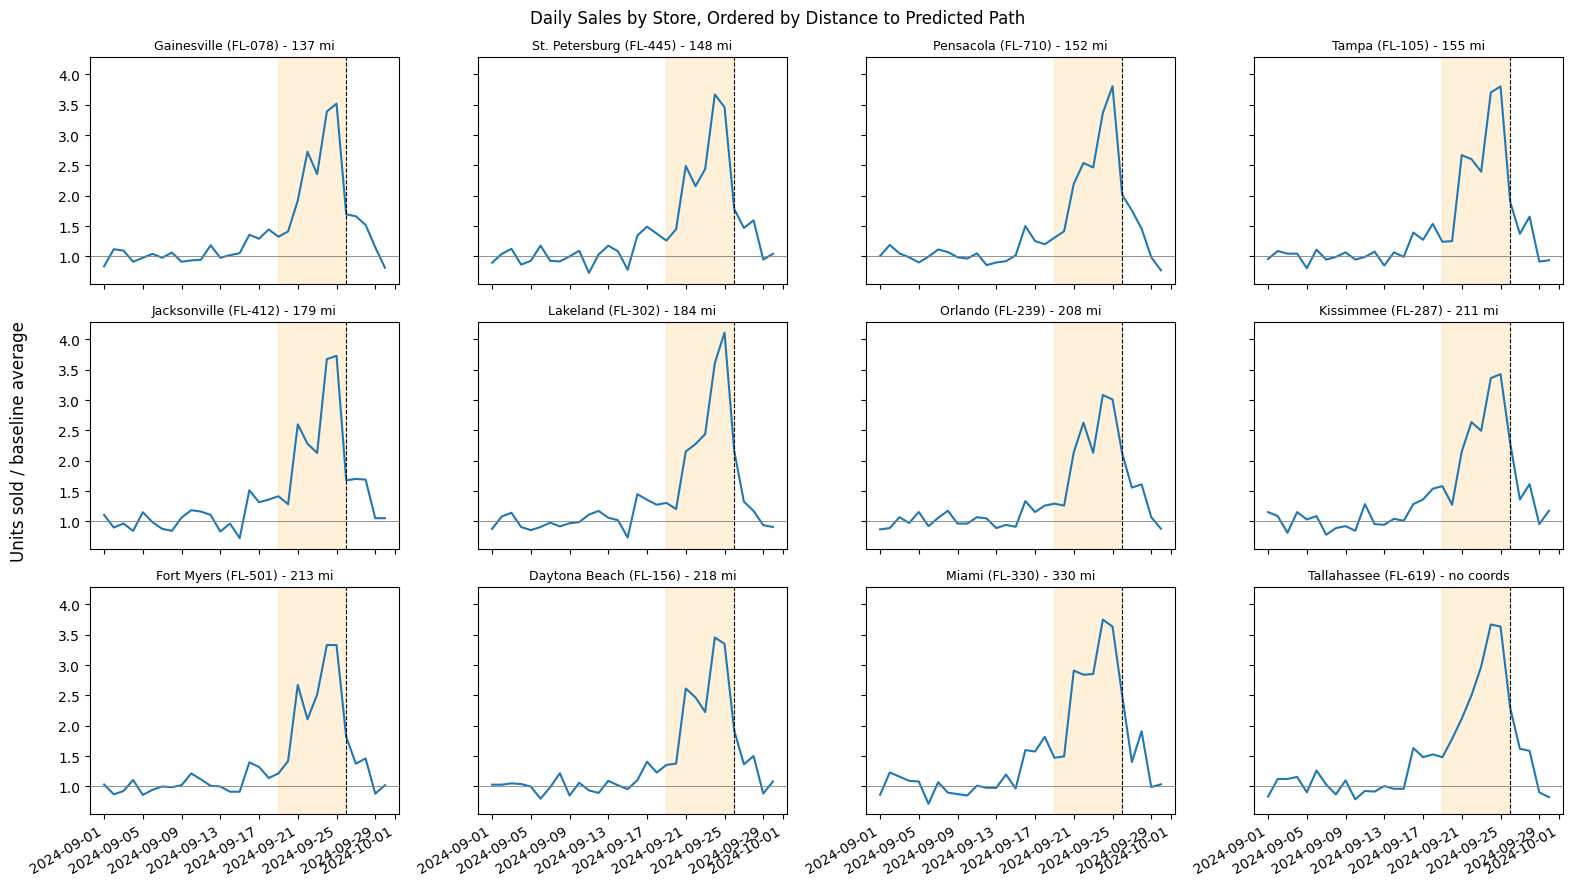

,store_id,city,miles_to_path,percent_increase,expected_increase,residual_z,increase_z,onset_days_before_landfall,outlier
3,FL-239,Orlando,208.0,122.10,144.97,-2.26,-1.87,10,True
1,FL-105,Tampa,155.0,152.45,139.11,1.32,0.63,10,False
6,FL-330,Miami,330.0,170.83,158.45,1.23,2.15,10,True
9,FL-501,Fort Myers,213.0,136.99,145.52,-0.84,-0.64,10,False
11,FL-710,Pensacola,152.0,144.26,138.78,0.54,-0.04,10,False
2,FL-156,Daytona Beach,218.0,140.66,146.07,-0.54,-0.34,9,False
8,FL-445,St. Petersburg,148.0,141.85,138.34,0.35,-0.24,10,False
4,FL-287,Kissimmee,211.0,141.92,145.30,-0.33,-0.24,9,False
7,FL-412,Jacksonville,179.0,144.51,141.76,0.27,-0.02,10,False
5,FL-302,Lakeland,184.0,144.31,142.32,0.20,-0.04,10,False


Outlier stores: ['Orlando', 'Miami']

=== CHECK A: Transaction-Level Breakdown for Entertainment ===

Daily units sold by product during surge:


product_name_clean,Monopoly Board Game,Playing Cards
date,,
2024-09-19,63,78
2024-09-20,43,78
2024-09-21,113,92
2024-09-22,97,126
2024-09-23,113,123
2024-09-24,173,153
2024-09-25,178,170


,Baseline Total Units,Surge Total Units,Absolute Increase,% Increase
product_name_clean,,,,
Monopoly Board Game,608,780,172,28.29
Playing Cards,829,820,-9,-1.09



=== CHECK B: Database Summary vs. Clean Transactions ===
Number of store-days with mismatches: 360 out of 360

Top Database Mismatches (Database Sales vs Transaction Sales):


,date,store_id,category,total_units,total_revenue,total_units_fractional,total_revenue_negative,tx_units,unit_difference
286,2024-09-24,FL-619,Entertainment,303.0,2596.57,False,False,25,278.0
294,2024-09-25,FL-330,Entertainment,267.0,3106.40,False,False,19,248.0
281,2024-09-24,FL-302,Entertainment,262.0,4524.00,False,False,30,232.0
297,2024-09-25,FL-501,Entertainment,257.0,4014.65,False,False,30,227.0
287,2024-09-24,FL-710,Entertainment,256.0,3508.22,False,False,32,224.0
277,2024-09-24,FL-105,Entertainment,244.0,1333.16,False,False,29,215.0
284,2024-09-24,FL-445,Entertainment,229.0,2100.28,False,False,29,200.0
278,2024-09-24,FL-156,Entertainment,210.0,2242.37,False,False,15,195.0
292,2024-09-25,FL-287,Entertainment,212.0,3616.37,False,False,19,193.0
268,2024-09-23,FL-287,Entertainment,208.0,761.72,False,False,19,189.0



=== CHECK C: Unmapped Inventory Codes & Potential Miscoding ===

Unmapped SKUs daily units on hand during surge:


sku,LEGACY-PT,MISC-001,OLD-BATT-50,UNKNOWN-99
date,,,,
2024-09-19,252,251,378,415
2024-09-20,1012,134,58,899
2024-09-21,58,69,269,79
2024-09-22,88,0,135,57
2024-09-23,117,148,102,87
2024-09-24,61,128,86,95
2024-09-25,31,57,180,109


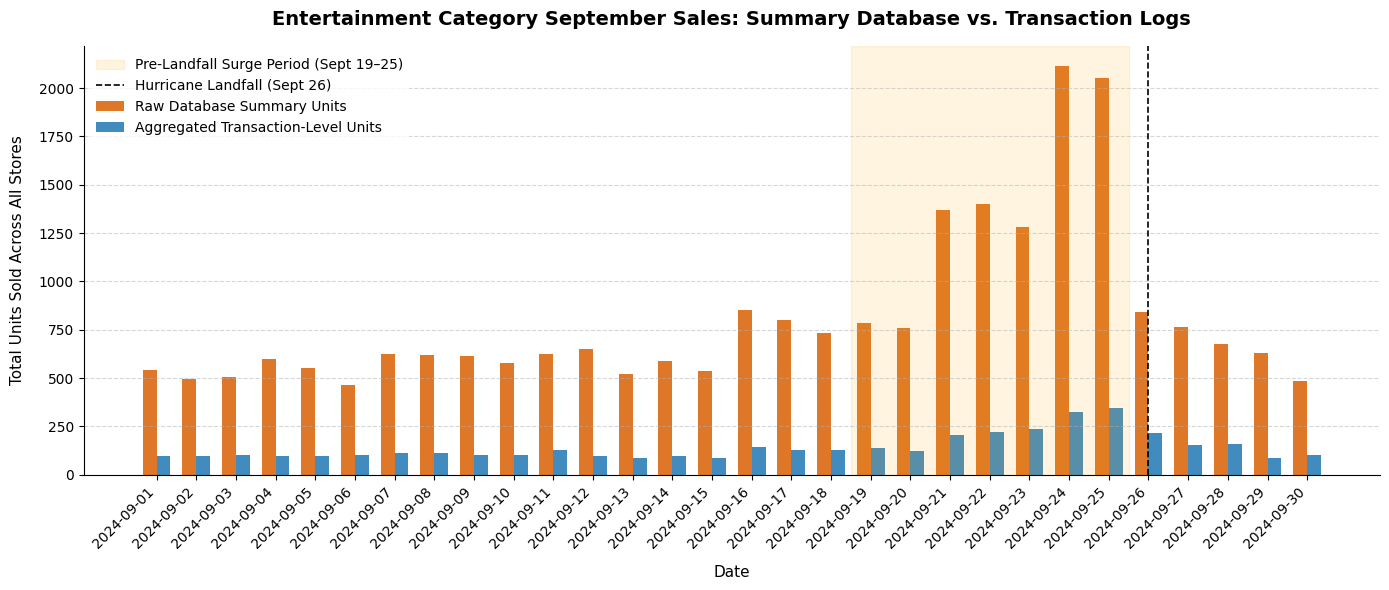

=== SURGE PERIOD COMPARISON (SEPT 19-25) ===
Database Summary reported:    9761 units
Actual Transaction Logs show: 1600 units
System Mapping Inflation:     8161 extra units


<Figure size 640x480 with 0 Axes>

In [ ]:
%run "ds_2002_project_working_doc.py"

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [ ]:
baseline_start = pd.Timestamp("2024-09-01")
baseline_end = pd.Timestamp("2024-09-14")

surge_start = pd.Timestamp("2024-09-19")
surge_end = pd.Timestamp("2024-09-25")

landfall = pd.Timestamp("2024-09-26")

q1_data = transactions_clean.dropna(
    subset=["timestamp", "quantity", "category_clean"]
).copy()

q1_data["date"] = q1_data["timestamp"].dt.normalize()

daily_units = (
    q1_data
    .groupby(["date", "category_clean"])["quantity"]
    .sum()
    .unstack("category_clean")
)

dates = pd.date_range(baseline_start, surge_end)

assert dates.isin(daily_units.index).all(), (
    "Some dates have no transaction records."
)

daily_units = daily_units.reindex(dates).fillna(0)

In [ ]:
baseline_avg = daily_units.loc[
    baseline_start:baseline_end
].mean()

surge_avg = daily_units.loc[
    surge_start:surge_end
].mean()

surge_results = pd.DataFrame({
    "baseline_daily_units": baseline_avg,
    "surge_daily_units": surge_avg
})

surge_results["additional_daily_units"] = (
    surge_results["surge_daily_units"]
    - surge_results["baseline_daily_units"]
)

surge_results["percent_increase"] = (
    surge_results["additional_daily_units"]
    / surge_results["baseline_daily_units"].replace(0, float("nan"))
    * 100
)

surge_results = surge_results.sort_values(
    "percent_increase", ascending=False
)

display(surge_results.round(2))

top5 = (
    surge_results
    .dropna(subset=["percent_increase"])
    .head(5)
    .index
)

,baseline_daily_units,surge_daily_units,additional_daily_units,percent_increase
category_clean,,,,
Breakfast,73.93,376.86,302.93,409.76
Emergency,356.57,1006.43,649.86,182.25
Electronics,69.93,175.86,105.93,151.48
Alcohol,61.57,138.86,77.29,125.52
Health,42.36,95.0,52.64,124.28
Entertainment,102.64,228.57,125.93,122.69
Household,85.36,176.29,90.93,106.53
Grocery,172.29,306.57,134.29,77.94
Baby,85.21,133.71,48.5,56.92


In [ ]:
display(
    surge_results[
        [
            "baseline_daily_units",
            "surge_daily_units",
            "percent_increase"
        ]
    ].head(5).round(2)
)

,baseline_daily_units,surge_daily_units,percent_increase
category_clean,,,
Breakfast,73.93,376.86,409.76
Emergency,356.57,1006.43,182.25
Electronics,69.93,175.86,151.48
Alcohol,61.57,138.86,125.52
Health,42.36,95.0,124.28


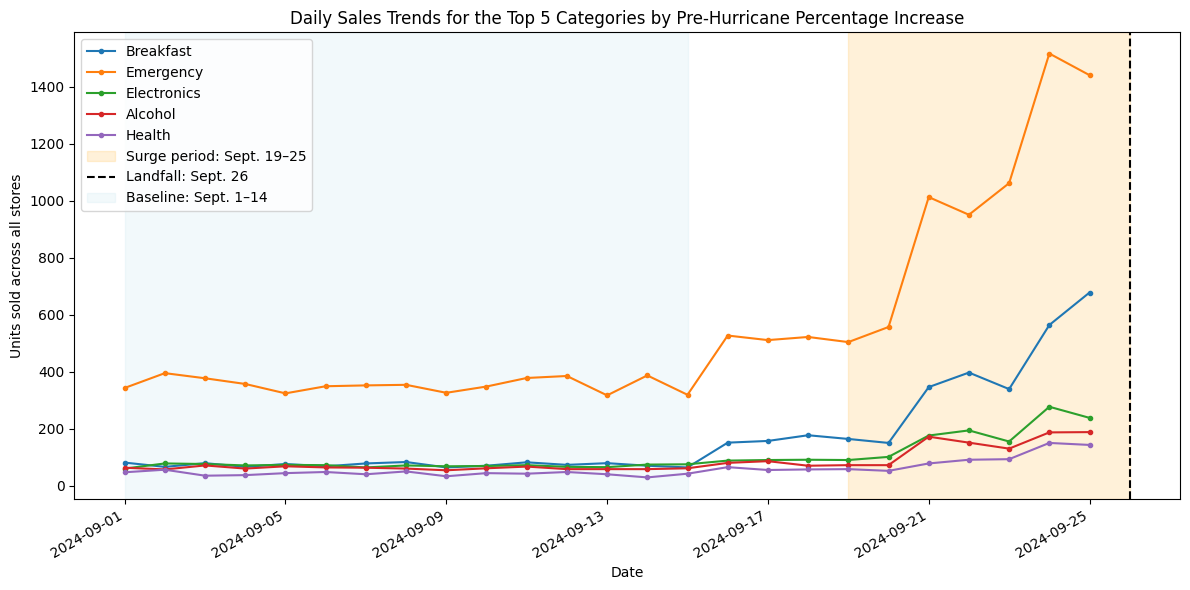

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

for category in top5:
    ax.plot(
        daily_units.index,
        daily_units[category],
        marker="o",
        markersize=3,
        label=category
    )

ax.axvspan(
    surge_start,
    landfall,
    color="orange",
    alpha=0.15,
    label="Surge period: Sept. 19–25"
)

ax.axvline(
    landfall,
    color="black",
    linestyle="--",
    label="Landfall: Sept. 26"
)

ax.set_title("Daily Sales Trends for the Top 5 Categories by Pre-Hurricane Percentage Increase")
ax.set_xlabel("Date")
ax.set_ylabel("Units sold across all stores")
ax.axvspan(
    baseline_start,
    baseline_end + pd.Timedelta(days=1),
    color="lightblue",
    alpha=0.15,
    label="Baseline: Sept. 1–14"
)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** _..._

During the September 19-25 pre-hurricane surge period compared to the September 1-14 bseline, overall category demand was led by Breakfast items, which had a 409.8% increase, followed by Emergency supplies having a 182.3% increase.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [ ]:
initial_skus = transactions["sku"].nunique()
canonical_products = transactions_clean["canonical_sku"].nunique()

print("Starting distinct SKUs:", initial_skus)
print("Final canonical products:", canonical_products)

family_sizes = (
    sku_map.groupby("canonical_sku")["sku"]
    .nunique()
    .sort_values(ascending=False)
)

largest_family = family_sizes.idxmax()

print("Largest consolidated family:", largest_family)
print("Original SKUs in this family:", family_sizes.max())

family_mapping = sku_map.loc[
    sku_map["canonical_sku"] == largest_family
]

display(family_mapping)

family_sales = transactions_clean.loc[
    transactions_clean["sku"].isin(family_mapping["sku"])
].dropna(subset=["quantity"]).copy()

before = (
    family_sales.groupby("sku")["quantity"]
    .sum()
    .rename("units_sold")
    .reset_index()
)

after = (
    family_sales.groupby("canonical_sku")["quantity"]
    .sum()
    .rename("units_sold")
    .reset_index()
)

print("BEFORE: sales split across original SKUs")
display(before)

print("AFTER: sales combined under one canonical product")
display(after)

before_mapping = clean_text_and_ids(
    remove_duplicates(transactions.copy())
)
before_mapping = clean_quantities(before_mapping)

after_mapping = before_mapping.merge(
    sku_map,
    on="sku",
    how="left",
    validate="many_to_one"
)

assert len(after_mapping) == len(before_mapping), (
    "Consolidation changed the row count"
)

assert after_mapping["canonical_sku"].notna().all(), (
    "Some SKUs did not match the mapping"
)

assert (
    before_mapping["quantity"].sum()
    == after_mapping["quantity"].sum()
), "Consolidation changed unit totals"

print("Validation passed: consolidation preserved rows and unit totals.")

Starting distinct SKUs: 45
Final canonical products: 20
Largest consolidated family: POPTART-STRAW
Original SKUs in this family: 4


,sku,canonical_sku,product_name_clean,category_clean
0,PT-12,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
1,SKU#459812,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
2,POPTART-STRAW,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
3,PT_STRAWBERRY,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast


BEFORE: sales split across original SKUs


,sku,units_sold
0,POPTART-STRAW,1300
1,PT-12,1381
2,PT_STRAWBERRY,1262
3,SKU#459812,1255


AFTER: sales combined under one canonical product


,canonical_sku,units_sold
0,POPTART-STRAW,5198


Validation passed: consolidation preserved rows and unit totals.


**Q2 answer:** We started with 45 distinct SKUs and consolidated them into 20 canonical products using a shared mapping table. The largest consolidated family was strawberry Pop-Tarts, which had four SKUs. All four were mapped to POPTART-STRAW.
Before consolidation, sales were split across four codes. After consolidation, they appeared as one combined product total, making overall demand easier to see. The assertions passed, so the mapping preserved both the number of transaction rows and total units sold. Consolidation changed how sales were grouped, not how many units were sold.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Detailed markdowns for each line of code is in our full working document. I decided to make this lab code more concise but the full markdown can be found in this notebook: https://github.com/clairinelou/walmart-hurricane-project/blob/main/notebooks/DS_2002_Project_Working_Doc.ipynb

In [ ]:
# API Set Up
BASE = "https://archive-api.open-meteo.com/v1/archive"
RETRY_STATUSES = {429, 500, 502, 503, 504}
WEATHER_VARS = ["precipitation_sum", "wind_speed_10m_max", "pressure_msl_mean"]

In [ ]:
# API Function
def daily_weather(start, end, lat=LAT, lon=LON, tz=LOCAL_TZ, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': ','.join(WEATHER_VARS),
        'timezone': tz,
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()["daily"]).rename(columns={"time": "date"})
        frame["date"] = pd.to_datetime(frame["date"])
        return frame

In [ ]:
# Weather for each store
STORE_TIMEZONES = {"FL-710": "America/Chicago"}

stores_with_coords = locations_clean.loc[~locations_clean["coordinates_missing"]]

weather_frames = []
for _, store in stores_with_coords.iterrows():
    tz = STORE_TIMEZONES.get(store["store_id"], "America/New_York")
    w = daily_weather(
        "2024-09-01", "2024-09-30",
        lat=store["latitude"], lon=store["longitude"], tz=tz
    )
    w["store_id"] = store["store_id"]
    weather_frames.append(w)
    time.sleep(0.5)  # be polite to the free API

weather_by_store = pd.concat(weather_frames, ignore_index=True)

assert not weather_by_store.duplicated(["store_id", "date"]).any()

print("Stores with weather:", weather_by_store["store_id"].nunique())
print("Skipped (no coordinates):",
      locations_clean.loc[locations_clean["coordinates_missing"], "store_id"].tolist())

Stores with weather: 11
Skipped (no coordinates): ['FL-619']


In [ ]:
# Validated Join
q3_sales = (
    transactions_clean
    .dropna(subset=["timestamp", "quantity"])
    .assign(date=lambda d: d["timestamp"].dt.normalize())
    .groupby(["store_id", "date", "category_clean"])["quantity"].sum()
    .unstack("category_clean", fill_value=0)
    .stack()
    .rename("units")
    .reset_index()
)
q3_sales["units"] = q3_sales["units"].astype(float)

baseline_mask = q3_sales["date"].between(baseline_start, baseline_end)
baseline_means = (
    q3_sales[baseline_mask]
    .groupby(["store_id", "category_clean"])["units"].mean()
    .rename("baseline_units")
)
q3_sales = q3_sales.join(baseline_means, on=["store_id", "category_clean"])
q3_sales["sales_index"] = q3_sales["units"] / q3_sales["baseline_units"]

q3_all = q3_sales.merge(
    weather_by_store,
    on=["store_id", "date"],
    how="left",
    validate="many_to_one",
    indicator=True
)

assert len(q3_all) == len(q3_sales), "Merge changed the number of sales rows"
assert np.isclose(q3_all["units"].sum(), q3_sales["units"].sum()), "Merge changed total units"
print(q3_all["_merge"].value_counts())
print("Sales rows with no weather (store has no coordinates):",
      q3_all.loc[q3_all["_merge"] == "left_only", "store_id"].unique())

q3 = q3_all.loc[q3_all["_merge"] == "both"].drop(columns="_merge")

print("Rows analyzed:", len(q3), "| stores:", q3["store_id"].nunique(),
      "| days:", q3["date"].nunique())

_merge
both          3300
left_only      300
right_only       0
Name: count, dtype: int64
Sales rows with no weather (store has no coordinates): ['FL-619']
Rows analyzed: 3300 | stores: 11 | days: 30


In [ ]:
# Correlation
weather_cols = {
    "precipitation_sum": "Precipitation",
    "wind_speed_10m_max": "Max wind speed",
    "pressure_msl_mean": "Mean pressure",
}

corr_table = (
    q3.groupby("category_clean")[["sales_index", *weather_cols]]
    .corr(method="spearman")
    .xs("sales_index", level=1)[list(weather_cols)]
    .rename(columns=weather_cols)
)
corr_table = corr_table.sort_values("Mean pressure")
display(corr_table.round(2))

,Precipitation,Max wind speed,Mean pressure
category_clean,,,
Emergency,-0.30,0.26,-0.38
Breakfast,-0.29,0.25,-0.38
Entertainment,-0.18,0.27,-0.29
Electronics,-0.21,0.23,-0.27
Household,-0.16,0.22,-0.24
Health,-0.17,0.23,-0.22
Grocery,-0.28,0.17,-0.21
Alcohol,-0.18,0.15,-0.20
Baby,-0.24,0.07,-0.12


In [ ]:
q3_total = (
    q3.groupby(["store_id", "date"])
    .agg(units=("units", "sum"), baseline_units=("baseline_units", "sum"),
         **{col: (col, "first") for col in weather_cols})
    .reset_index()
    .sort_values(["store_id", "date"])
)
q3_total["sales_index"] = q3_total["units"] / q3_total["baseline_units"]

lags = range(-7, 8)
lag_rows = []
for lag in lags:
    shifted = q3_total.copy()
    for col in weather_cols:
        shifted[col] = shifted.groupby("store_id")[col].shift(-lag)
    row = {"lag_days": lag}
    for col, label in weather_cols.items():
        row[label] = shifted["sales_index"].corr(shifted[col], method="spearman")
    lag_rows.append(row)

lag_table = pd.DataFrame(lag_rows).set_index("lag_days")
display(lag_table.round(2))

best_lags = pd.DataFrame({
    "best_lag_days": lag_table.abs().idxmax(),
    "correlation_at_best_lag": [lag_table.loc[lag_table[c].abs().idxmax(), c]
                                for c in lag_table.columns],
    "correlation_at_lag_0": lag_table.loc[0],
})
display(best_lags.round(2))

,Precipitation,Max wind speed,Mean pressure
lag_days,,,
-7,-0.14,-0.12,-0.41
-6,-0.25,-0.17,-0.51
-5,-0.39,-0.22,-0.51
-4,-0.53,-0.22,-0.37
-3,-0.45,-0.15,-0.31
-2,-0.41,0.01,-0.34
-1,-0.42,0.13,-0.37
0,-0.31,0.27,-0.39
1,-0.27,0.27,-0.43


,best_lag_days,correlation_at_best_lag,correlation_at_lag_0
Precipitation,-4,-0.53,-0.31
Max wind speed,4,0.35,0.27
Mean pressure,-6,-0.51,-0.39


**Q3 answer, with its caveat:** Barometric pressure was the weather indicator that was most consistently related to sales. Sales were higher in lower-pressure days in 9 out of the 10 categories, most strongly for Emergency and Breakfast (Spearman -0.38). Wind was positively correlated and precipitation was negatively correlated with sales in every category. The clearest lag was for wind (+0.35 vs. +0.27 same-day). Sales lined up best with wind four days later, which suggests people stocked up before the storm. The join kept all 3,600 sales rows, and all the Q3 weather is taken live from Open-Meteo. We only dropped the 300 Tallahassee rows, which have no coordinates. We analyzed 3,300 rows total. The main caveat is that n is small. The correlations cover only 30 days of a single storm, and all 11 stores share the same timeline, so this is not 330 independent data points and is more like 30, so these results are not conclusive.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Malia has completed writing all the code, creating graphs and charts, markdown explanations have also been added in. We are just proofreading, confirming and finalizing it.

**Q5 (signal or artifact):** Anika has completed writing all the code, creating graphs and charts, markdown explanations have also been added in. We are just proofreading, confirming and finalizing it.

### Self-check

In [ ]:
progress = {
    'q1_multiple': surge_results.loc['Breakfast', 'percent_increase'] / 100 + 1,            # TODO: a number
    'q1_baseline_window': '2024-09-01 to 2024-09-14',   # TODO: stated explicitly
    'q2_canonical_products': canonical_products,  # TODO: a number
    'q3_join_rows_preserved': len(q3_all) == len(q3_sales), # TODO: True/False
    'q3_days_in_correlation': q3["date"].nunique(), # TODO: a number
    'charts_with_message_titles': '8',  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.097584541062801
PASS - q1_baseline_window = 2024-09-01 to 2024-09-14
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 8
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a) One finding that surprised my team was the fact that there were 9671 units sold for the entertainment category. This seemed like a shockingly high value, so to fact check it I created a direct comparison to tell if the amount noted sold also matched with the amount of receipts from customers. This served as means of fact-checking our data. The results showed that there were actually only 780 units of monopoly sold and 820 units of playing card decks sold, so a total of 1600 units sold.

b) One number we are the elast confident in is the percent increase in the breakfast category (baseline period to surge period) from question 1. We found that breakfast increased by 409.76%, much larger than any other category. The second largest was emergency at 182.25%, which is less than half of breakfast's increase. However, breakfast had a much smaller baseline (73.93 daily untis versus 356.57 for emergency), so a smaller increase produces a larger percent change. Because percent change is sensitive to the small baseline, the large percent increase could overstate how much breakfast demand grew compared to the other categories, which is important to keep in mind for our analysis.